## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = True # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

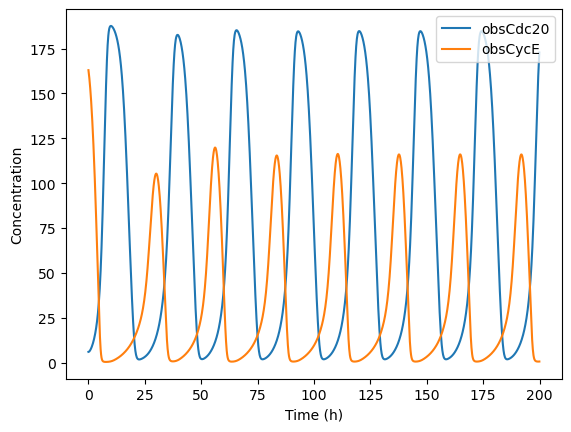

In [7]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0.6
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 1
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


<Axes: xlabel='Time (h)', ylabel='Concentration'>

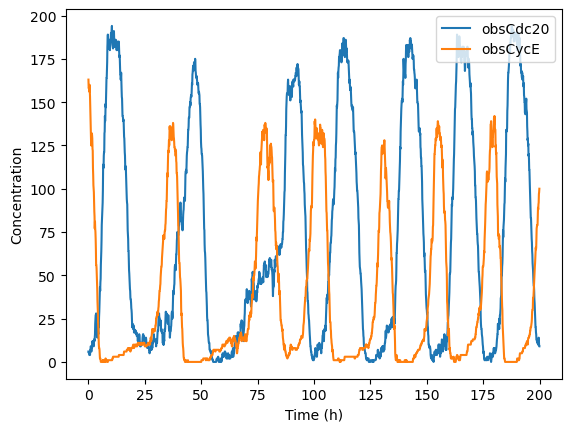

In [8]:
sim_stoch = BngSimulator(model, tspan=t, verbose=False)
sim_stoch_res = sim_stoch.run(method='ssa', verbose=False)
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_stoch_res.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


### Run example simulation
Use low stiffness and DMSO treatment as condition. Must use more cells to get decent output.

In [9]:
start_time = datetime.datetime.now()

init = 3
run_time = 120
observed_cells_time = 120
condition = "55 kPa erlotinib"

In [10]:
# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
current_time = datetime.datetime.now()
print(f'elapsed time is {(current_time-start_time)/60} minutes')

55 kPa erlotinib
BAXm_0
BCL2_0
elapsed time is 0:00:01.221640 minutes


In [11]:
import fracprolif as fp

In [12]:
population_history = population_df
parameters_sim = {}

In [13]:
population_df

,Old ID,New ID,Lineage,Event,Start Time,Birth Time,End Time,Starting Cell,Lifetime
0,0,0,Initial cell,Mitosis,0.000000,Initial cell,0.501672,True,0.501672
1,0,71,0,Mitosis,0.501672,0.501672,22.575251,False,22.073579
2,0,72,71,Mitosis,22.575251,22.575251,51.973244,False,29.397993
3,0,73,72,Mitosis,51.973244,51.973244,104.849498,False,52.876254
4,0,74,73,End of experiment,104.849498,104.849498,120.000000,False,15.150502
...,...,...,...,...,...,...,...,...,...
134,66,66,45,End of experiment,93.712375,93.712375,120.093769,False,26.381394
135,67,67,47,End of experiment,105.752508,105.752508,120.091209,False,14.338701
136,68,68,130,End of experiment,112.173913,112.173913,120.086957,False,7.913043
137,69,69,132,End of experiment,111.929673,111.929673,120.082776,False,8.153103


### New plotting function
Use seaborn and pandas. Should also save output files as csv (or parquet or feather) to maximize cross compatibility. Simple save procedure once data are in pandas DataFrame.  

In [14]:
model.parameters['CycDi_0'].value

0.0

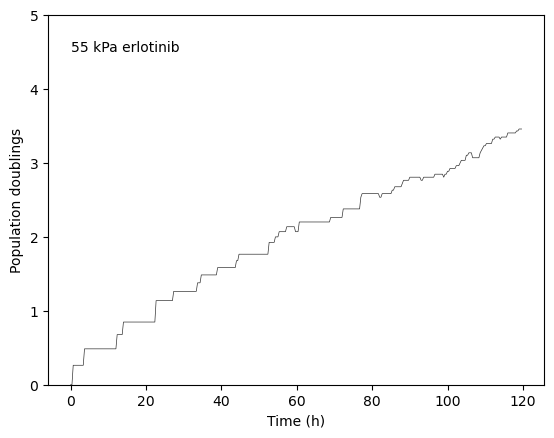

In [15]:
fig, ax = make_fig(cell_count, run_time, title=condition)
add_plot(cell_count, run_time, fig, ax, title=condition)

In [16]:
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0   0.501672
1         False       False  False    0.501672  22.073579
2         False       False  False   22.575251  29.397993
3         False       False  False   51.973244  52.876254
4         False        True  False  104.849498  15.050167
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 3.612040133779}


(0.0, 125.0)

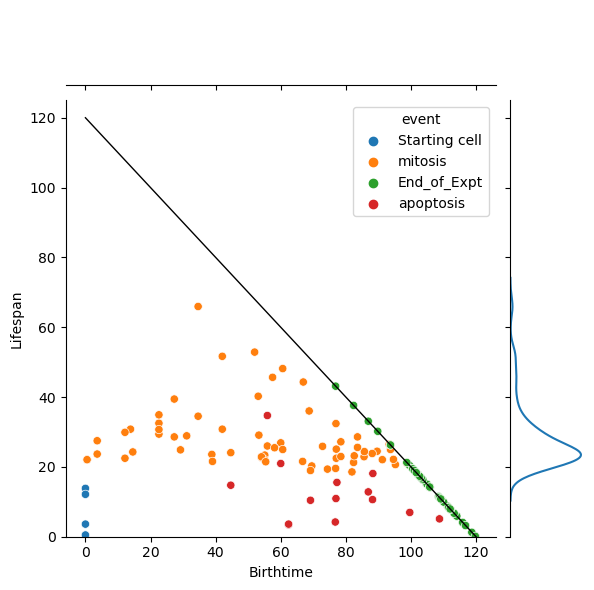

In [17]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [18]:
all_events_simulated

,event,Birthtime,Lifespan
0,Starting cell,0,0.501672
1,mitosis,0.501672,22.073579
2,mitosis,22.575251,29.397993
3,mitosis,51.973244,52.876254
4,End_of_Expt,104.849498,15.050167
...,...,...,...
134,End_of_Expt,93.712375,26.280702
135,End_of_Expt,105.752508,14.237724
136,End_of_Expt,112.173913,7.811594
137,End_of_Expt,112.031587,7.949275


  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          True       False  False           0   0.501672
1         False       False  False    0.501672  22.073579
2         False       False  False   22.575251  29.397993
3         False       False  False   51.973244  52.876254
4         False        True  False  104.849498  15.050167
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 3.612040133779}


(0.0, 125.0)

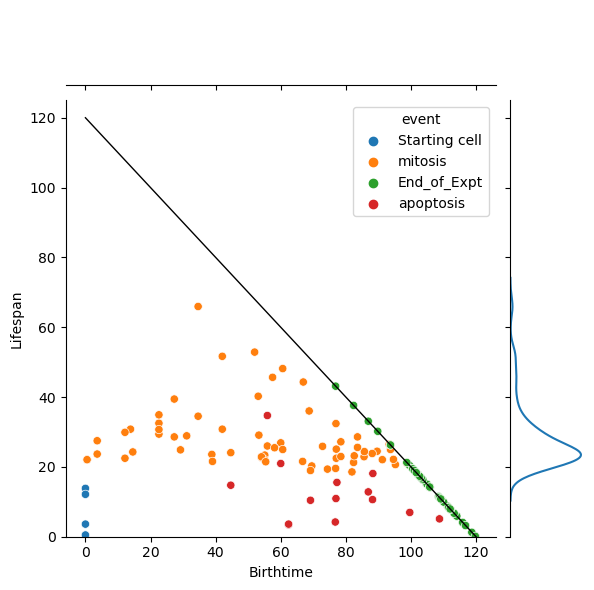

In [19]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True)
all_events_simulated = call_events(run_time, IMT_eoe_counts) #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [20]:
test = fit_DIP(cell_count, run_time)
test

0.025936549753830928

In [21]:
model.parameters['V_Di'].value

0.6

In [22]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

In [23]:
SAVE_DIR

PosixPath('/Users/darren/ECM_mod_output')

In [24]:
condition = "55 kPa erlotinib"

In [25]:
start_time = datetime.datetime.now()

conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']


for condition in conditions:
    for num in range(3):
        init = 5
        
        (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_orig_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")
        current_time = datetime.datetime.now()
        print(f'elapsed time is {(current_time-start_time)/60} minutes')

4 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_0_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_0_orig_param_orig.csv...
elapsed time is 0:00:00.919147 minutes
4 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_1_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_1_orig_param_orig.csv...
elapsed time is 0:00:02.127896 minutes
4 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_4 kPa erlotinib_2_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_4 kPa erlotinib_2_orig_param_orig.csv...
elapsed time is 0:00:03.358769 minutes
4 kPa DMSO
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_4 kPa DMSO_0_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_4 kPa DMSO_0_orig_param_orig.csv...
elapsed time is 0:00:06.646182 minutes
4 kPa DMSO
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mo

In [26]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

for condition in conditions:
    for num in range(3):
        init = 10
        
        (check, population_df, cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, thr=[0.26, 0.14], return_plot=False, bypass=True)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

0.6 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_0_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_0_param_orig.csv...
0.6 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_1_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_1_param_orig.csv...
0.6 kPa erlotinib
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_0.6 kPa erlotinib_2_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_0.6 kPa erlotinib_2_param_orig.csv...
0.6 kPa DMSO
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_0.6 kPa DMSO_0_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_0.6 kPa DMSO_0_param_orig.csv...
0.6 kPa DMSO
BAXm_0
BCL2_0
Saving to /Users/darren/ECM_mod_output/cells_0.6 kPa DMSO_1_param_orig.csv...
Saving to /Users/darren/ECM_mod_output/cellcount_0.6 kPa DMSO_1_param_orig.csv...
0.6 kPa DMSO
BAXm_0


In [27]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO', '4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']

for condition in conditions:
    runIMTs(20, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names, 200, 'no_inhib')

0.6 kPa erlotinib
BAXm_0
BCL2_0


NameError: name 'IMT_eoe_counts' is not defined